# Предсказание выживания персонажей "Игры престолов"

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/drive/1h0riRr_19lPa39qUFo_VDRms7T6E1ToT?usp=sharing)

Задача и датасет взяты из курса Deep Learning School (МФТИ).

Цель работы - построить модель, которая по данным о персонаже предсказывает значение `isAlive`: 1, если персонаж жив, и 0, если он умер.

Это задача бинарной классификации. Основная метрика качества - accuracy.

В работе я сначала изучу данные и подготовлю признаки, затем сравню несколько моделей и сформирую прогноз для тестовой выборки.

## 1. Загрузка данных и библиотек

In [2]:
!gdown 1h99toeF7lZ2I3iJwehgKO-QQmDaOe_O3 # test dataset
!gdown 1XL0VTygpZj-ZAuTNRBgApZTPQyNDnT-v # train dataset

Downloading...
From: https://drive.google.com/uc?id=1h99toeF7lZ2I3iJwehgKO-QQmDaOe_O3
To: /content/game_of_thrones_test.csv
100% 37.3k/37.3k [00:00<00:00, 7.77MB/s]
Downloading...
From: https://drive.google.com/uc?id=1XL0VTygpZj-ZAuTNRBgApZTPQyNDnT-v
To: /content/game_of_thrones_train.csv
100% 138k/138k [00:00<00:00, 62.8MB/s]


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
data = pd.read_csv("game_of_thrones_train.csv", index_col='S.No')

## 2. Анализ и подготовка признаков

### 2.1 Первичный обзор данных

Обучающая выборка содержит 1557 персонажей. Сначала посмотрю на текстовые и числовые признаки, количество уникальных значений и пропуски.

In [5]:
data.describe(include='object').T

,count,unique,top,freq
name,1557,1557,Melara Hetherspoon,1
title,717,195,Ser,306
culture,488,51,Northmen,94
mother,18,16,Rhaenyra Targaryen,2
father,22,19,Daemon Targaryen,2
heir,21,20,Jaehaerys Targaryen,2
house,1176,315,House Frey,89
spouse,200,186,Walder Frey,6


In [6]:
data.describe(include=['int64', 'float64']).T[['count', 'min', 'max']]

,count,min,max
male,1557.0,0.0,1.0
dateOfBirth,279.0,-25.0,299.0
book1,1557.0,0.0,1.0
book2,1557.0,0.0,1.0
book3,1557.0,0.0,1.0
book4,1557.0,0.0,1.0
book5,1557.0,0.0,1.0
isAliveMother,18.0,0.0,1.0
isAliveFather,22.0,0.0,1.0
isAliveHeir,21.0,0.0,1.0


In [7]:
data.isna().sum(axis=0)

,0
name,0
title,840
male,0
culture,1069
dateOfBirth,1278
mother,1539
father,1535
heir,1536
house,381
spouse,1357


В данных много пропусков. Возраст и год рождения отсутствуют у 1278 персонажей, культура - у 1069, а сведения о родственниках заполнены только для небольшой части выборки.

Удаление всех строк с пропусками привело бы к большой потере данных, поэтому пропуски будут обрабатываться отдельно для каждого выбранного признака.

Колонка `name` уникальна для всех 1557 строк и фактически является идентификатором. `title`, `house` и имена родственников содержат много редких значений, поэтому в первую версию модели я их не включаю.

### 2.2 Преобразование `popularity`

Сначала посмотрю на исходное распределение популярности персонажей.

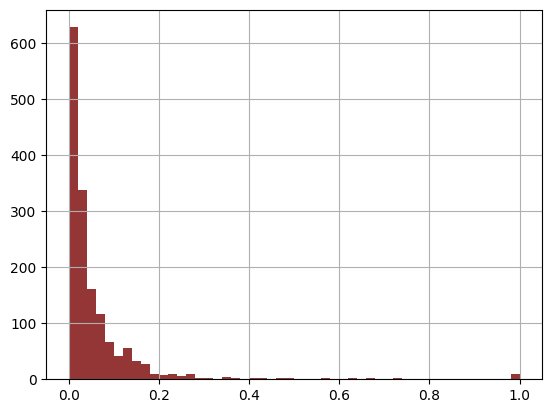

In [8]:
hist = data['popularity'].hist(bins=50, color='#943636')

Распределение `popularity` сильно скошено вправо. Большая часть персонажей имеет популярность около нуля, а высокие значения встречаются редко.

Чтобы уменьшить влияние длинного правого хвоста и сделать различия между небольшими значениями заметнее, применю логарифмическое преобразование.

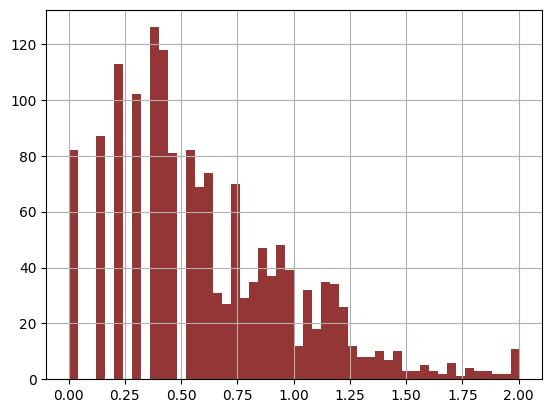

In [9]:
M = 100
popularity_log = np.log10(data['popularity']*M+1)
hist = popularity_log.hist(bins=50, color='#943636')

In [10]:
data['popularity_log'] = popularity_log

Для преобразования использована формула `log10(popularity * 100 + 1)`. Прибавление единицы позволяет корректно обработать нулевые значения.

После логарифмирования крупные значения сжимаются, а распределение становится удобнее для модели. В итоговый набор признаков будет включён `popularity_log`, а не исходный `popularity`.

### 2.3 Признак `numDeadRelations`

Теперь посмотрю на распределение количества связей персонажа с умершими персонажами.

<Axes: >

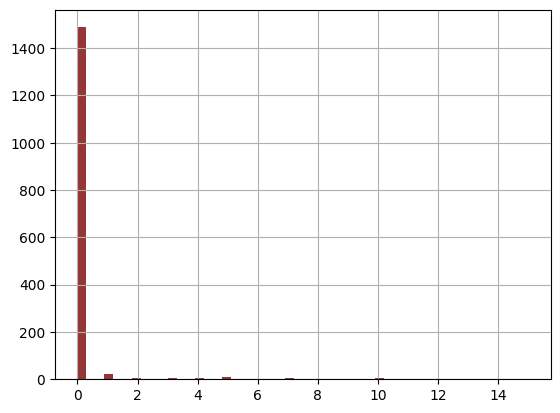

In [11]:
data['numDeadRelations'].hist(bins=50, color='#943636')

Большая часть значений `numDeadRelations` равна нулю, а положительные значения встречаются редко. Использование исходного количества может сделать модель чувствительной к небольшим и нестабильным группам.

Поэтому вместо количества создаю бинарный признак, который показывает, были ли у персонажа какие-либо связи с умершими.

In [12]:
data['boolDeadRelations'] = (data.numDeadRelations > 0).astype(int)

### 2.4 Обработка возраста

Возраст известен только у 279 персонажей из 1557. Удалять строки с пропусками нельзя, так потеряется больше 80% данных. Поэтому создаю два признака: значение возраста (пропуск заменяю нулём) и флаг того, что возраст неизвестен.

In [13]:
data['age_value'] = data['age'].fillna(0)
data['age_no_data'] = [1 if np.isnan(x) else 0 for x in data['age']]

В `age_value` пропуски заменены нулями, а `age_no_data` показывает, был ли возраст известен.

Эти признаки нужно использовать вместе. Ноль в `age_value` сам по себе не позволяет отличить неизвестный возраст от реального нулевого возраста.

`dateOfBirth` отдельно в модель не включаю, так как эта колонка содержит те же пропуски и частично дублирует информацию о возрасте.

### 2.5 Обработка культуры

В исходной колонке `culture` много пропусков и редких значений. Сначала посмотрю на частоты категорий.

In [14]:
data['culture'].value_counts(dropna=False)

,count
culture,
NaN,1069
Northmen,94
Ironborn,91
Free Folk,45
Braavosi,39
Valyrian,28
Ghiscari,17
Dornish,17
Dothraki,17


В `culture` содержится 51 уникальное значение, а у 1069 персонажей культура не указана.

Некоторые категории отличаются только регистром, например `Northmen` и `northmen`. Перед группировкой названия будут переведены в нижний регистр.

Чтобы уменьшить количество редких категорий, исходные культуры объединяются в более крупные географические группы.

In [15]:
cultures_grouped = {
    'Old Nations': ['valyrian', 'first men', 'andal', 'andals', 'rhoynar'],
    'the North': ['northmen', 'northern mountain clans', 'crannogmen'],
    'the Iron Islands': ['ironborn', 'ironmen'],
    'the Mountain and the Vale': ['valemen', 'vale', 'vale mountain clans',
                              'sistermen'],
    'the Isles and Rivers': ['riverlands', 'rivermen'],
    'the Rock': ['westerman', 'westermen', 'westerlands'],
    'the Stormlands': ['stormlander', 'stormlands'],
    'the Reach': ['reach', 'reachmen', 'the reach'],
    'Dorne': ['dornish', 'dornishmen', 'dorne'],
    'Essos Nations': ['astapor', 'astapori', 'braavosi', 'braavos', 'tyroshi', 'lysene', 'lyseni',
                      'myrish', 'pentoshi', 'qartheen', 'qarth', 'dothraki',
                      'lhazarene', 'lhazareen','meereen', 'meereenese',
                      'norvoshi', 'qohor', 'summer isles', 'summer islands',
                      'summer islander', 'asshai', "asshai'i", 'norvos', 'ghiscari',
                      'ghiscaricari'],
    'Other Nations': ['ibbenese', 'westeros', 'free folk', 'wildling', 'wildlings', 'naathi']}

In [16]:
cultures_grouped_inverted = {}
for k in cultures_grouped.keys():
  for v in cultures_grouped[k]:
    cultures_grouped_inverted.update({v:k})

In [17]:
data['cultures_grouped'] = data['culture'].str.lower().map(cultures_grouped_inverted)

In [18]:
data['cultures_grouped'] = data['cultures_grouped'].fillna('culture_no_data')

После группировки вместо 51 исходной категории получилось 12 укрупнённых категорий, включая `culture_no_data`.

Это уменьшает число редких значений и позволяет использовать один и тот же способ обработки культуры для обучающей и тестовой выборок.

### 2.6 Проверка созданных признаков

Теперь посмотрю на количество уникальных значений и основные характеристики числовых колонок.

In [19]:
data.nunique()

,0
name,1557
title,195
male,2
culture,51
dateOfBirth,105
mother,16
father,19
heir,20
house,315
spouse,186


In [20]:
data.describe(include = ['int64', 'float64']).T[['count', 'min', 'max']].assign(N_unique_values = data.nunique())

,count,min,max,N_unique_values
male,1557.0,0.0,1.000000,2
dateOfBirth,279.0,-25.0,299.000000,105
book1,1557.0,0.0,1.000000,2
book2,1557.0,0.0,1.000000,2
book3,1557.0,0.0,1.000000,2
book4,1557.0,0.0,1.000000,2
book5,1557.0,0.0,1.000000,2
isAliveMother,18.0,0.0,1.000000,2
isAliveFather,22.0,0.0,1.000000,2
isAliveHeir,21.0,0.0,1.000000,2


Большинство колонок со значениями от 0 до 1 являются бинарными. Исключением является `popularity`: несмотря на тот же диапазон, этот признак имеет 117 уникальных значений и является непрерывным.

Созданные признаки `boolDeadRelations` и `age_no_data` принимают только значения 0 и 1. В `popularity_log`, `age_value` и бинарных признаках, выбранных для модели, пропусков нет.

### 2.7 Кодирование культуры

Для включения `cultures_grouped` в модель применю one-hot-кодирование.

In [22]:
culture_encoded = pd.get_dummies(data['cultures_grouped'], prefix='culture', dtype=int)

После one-hot-кодирования культура представлена 12 бинарными колонками.

Исходные `culture` и `cultures_grouped` в итоговую матрицу признаков добавляться не будут, так как их информация уже содержится в новых колонках.

### 2.8 Корреляции количественных признаков

Корреляционная матрица поможет найти признаки, которые содержат похожую информацию.

<Axes: >

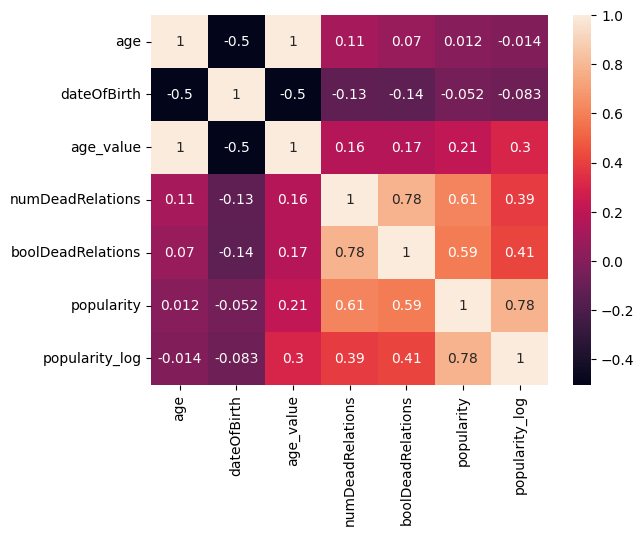

In [23]:
corr_matrix = data[['age', 'dateOfBirth', 'age_value', 'numDeadRelations', 'boolDeadRelations', 'popularity', 'popularity_log']].corr()
sns.heatmap(corr_matrix, annot=True)

Самые сильные связи ожидаемо возникают между исходными признаками и их преобразованными версиями.

Корреляция `age` и `age_value` равна 1 на строках с известным возрастом. Для `numDeadRelations` и `boolDeadRelations`, а также для `popularity` и `popularity_log` корреляция равна 0.78.

Чтобы не добавлять в модель дублирующую информацию, оставлю только обработанную версию каждого признака:

- `age_value` вместе с `age_no_data`;
- `boolDeadRelations`;
- `popularity_log`.

In [24]:
num_features = data[['age_value', 'age_no_data', 'boolDeadRelations', 'popularity_log']]

### 2.9 Связь признаков с целевой переменной

Далее посмотрю, как выбранные признаки связаны с `isAlive`.

Так как целевая переменная принимает значения 0 и 1, её среднее равно доле живых персонажей. Для категориальных и бинарных признаков буду сравнивать среднее `isAlive` и размер каждой группы.

In [25]:
data['isAlive'].mean()

np.float64(0.7784200385356455)

Доля живых персонажей равна 0.7784, то есть около 77.8% объектов относятся к классу 1.

Классы несбалансированы. Поэтому accuracy обученной модели нужно сравнивать с простым baseline, который всегда предсказывает самый частый класс.

In [26]:
data.groupby(data['isAliveSpouse'], dropna=False)['isAlive'].agg(['mean', 'count'])

,mean,count
isAliveSpouse,,
0.0,0.619048,42
1.0,0.753165,158
NaN,0.786293,1357


In [27]:
data.groupby(data['isMarried'], dropna=False)['isAlive'].agg(['mean', 'count'])

,mean,count
isMarried,,
0,0.786293,1357
1,0.725000,200


`isAliveSpouse` заполнен только для 200 женатых персонажей. Группа с пропуском полностью совпадает с `isMarried = 0`, поэтому эти признаки частично дублируют друг друга.

Среди неженатых персонажей доля живых равна 78.6%, среди женатых - 72.5%. Для первой модели оставлю `isMarried`, а `isAliveSpouse` не буду использовать из-за большого количества пропусков.

In [28]:
data.groupby(data['boolDeadRelations'], dropna=False)['isAlive'].agg(['mean', 'count'])

,mean,count
boolDeadRelations,,
0,0.794355,1488
1,0.434783,69


In [29]:
data.groupby(data['numDeadRelations'], dropna=False)['isAlive'].agg(['mean', 'count'])

,mean,count
numDeadRelations,,
0,0.794355,1488
1,0.625000,24
2,1.000000,4
3,0.250000,4
4,0.285714,7
5,0.400000,10
6,0.333333,3
7,0.142857,7
8,0.500000,2


Наличие связей с умершими персонажами заметно связано с целевой переменной. При `boolDeadRelations = 0` живы 79.4% персонажей, а при `boolDeadRelations = 1` - только 43.5%.

Для отдельных положительных значений `numDeadRelations` группы слишком малы, поэтому средние сильно колеблются. Бинарный вариант признака выглядит более устойчивым и будет использован в модели.

In [30]:
data.groupby(data['cultures_grouped'], dropna=False)['isAlive'].agg(['mean', 'count'])

,mean,count
cultures_grouped,,
Dorne,0.952381,21
Essos Nations,0.834862,109
Old Nations,0.281250,32
Other Nations,0.701754,57
culture_no_data,0.781104,1069
the Iron Islands,0.884211,95
the Isles and Rivers,0.700000,10
the Mountain and the Vale,0.840000,25
the North,0.777778,108


Доля живых различается между культурами. Например, для `Old Nations` она равна 28.1%, для `Essos Nations` - 83.5%, для `the Iron Islands` - 88.4%.

Результаты небольших групп нужно интерпретировать осторожно. Например, в `the Stormlands` всего 4 персонажа, поэтому значение 100% не является устойчивой оценкой.

Несмотря на различия в размере групп, признак культуры может быть полезен и остаётся в модели после one-hot-кодирования.

In [31]:
features_with_target = num_features.copy()
features_with_target['isAlive'] = data['isAlive']

target_corr = features_with_target.corr()
target_corr['isAlive']

,isAlive
age_value,-0.181938
age_no_data,0.113629
boolDeadRelations,-0.178177
popularity_log,-0.242497
isAlive,1.000000


In [32]:
binary_columns = ['male', 'book1', 'book2', 'book3', 'book4', 'book5',
                  'isNoble', 'isMarried']

binary_corr = data[binary_columns +['isAlive']].corr()
binary_corr['isAlive']

,isAlive
male,-0.148290
book1,-0.112468
book2,-0.055998
book3,0.018427
book4,0.284014
book5,0.032531
isNoble,-0.060572
isMarried,-0.049381
isAlive,1.000000


Среди обработанных количественных признаков самая заметная линейная связь с целью у `popularity_log` с корреляцией -0.242. Для `age_value` и `boolDeadRelations` корреляции также отрицательные.

Среди бинарных признаков выделяется `book4` с корреляцией 0.284. Далее идут `male` с корреляцией -0.148 и `book1` с корреляцией -0.112.

Небольшая индивидуальная корреляция не означает, что признак бесполезен в сочетании с другими. Поэтому готовые бинарные признаки без пропусков сохраняются в первой версии модели.

### 2.10 Итоговый набор признаков

В модель будут включены обработанные числовые признаки, готовые бинарные признаки и one-hot-представление культуры. Исходные текстовые колонки и необработанные версии преобразованных признаков в `X` не добавляются.

In [33]:
selected_features = ['male', 'book1', 'book2', 'book3', 'book4', 'book5', 'isMarried',
    'isNoble', 'age_value','age_no_data', 'boolDeadRelations', 'popularity_log']

base_features = data[selected_features].copy()

In [34]:
X = pd.concat([base_features, culture_encoded], axis=1)
y = data['isAlive'].copy()

In [35]:
from sklearn.model_selection import train_test_split

In [36]:
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

Итоговая матрица `X` содержит 24 признака: 12 основных числовых и бинарных колонок и 12 one-hot-признаков культуры. В ней нет пропусков и текстовых значений.

Данные разделены в пропорции 80/20. Параметр `stratify=y` сохраняет долю классов в train и validation, а `random_state=42` фиксирует разбиение для сравнения моделей.

## 3. Обучение и оценка моделей

Все модели будут сравниваться на одном и том же validation-наборе. Это позволяет связать разницу в accuracy с моделью и параметрами, а не с новым случайным разбиением.

### 3.1 Logistic Regression

В качестве первой модели использую Logistic Regression без дополнительной настройки гиперпараметров.

In [37]:
from sklearn.linear_model import LogisticRegression

In [38]:
logreg = LogisticRegression(max_iter=10000, random_state=42)

In [39]:
logreg.fit(X_train, y_train)
y_pred_logreg = logreg.predict(X_val)

In [41]:
from sklearn.metrics import accuracy_score

In [42]:
accuracy = accuracy_score(y_val, y_pred_logreg)
print("Accuracy: %.4f" % accuracy)

Accuracy: 0.7756


In [43]:
class_shares = y_val.value_counts(normalize=True)
class_shares

,proportion
isAlive,
1,0.778846
0,0.221154


In [44]:
majority_baseline = class_shares.max()
majority_baseline

0.7788461538461539

In [45]:
from sklearn.metrics import confusion_matrix

In [46]:
confusion = confusion_matrix(y_val, y_pred_logreg)
confusion

array([[ 16,  53],
       [ 17, 226]])

Logistic Regression получила accuracy 0.7756. Majority baseline равен 0.7788, поэтому линейная модель не превзошла предсказание самого частого класса.

По матрице ошибок модель правильно определила 16 умерших и 226 живых персонажей. По сравнению с постоянным предсказанием класса 1 модель исправила 16 ошибок, но при этом ошибочно отнесла 17 живых персонажей к умершим. В результате число правильных ответов уменьшилось на один.

### 3.2 Logistic Regression со стандартизацией

Проверю, изменится ли качество после приведения признаков к сопоставимому масштабу.

`Pipeline` обучает `StandardScaler` только на тренировочной части, а затем применяет те же параметры к validation. Это позволяет избежать утечки информации.

In [47]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

In [48]:
pipeline = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=42))
pipeline.fit(X_train, y_train)
y_pred_scaled = pipeline.predict(X_val)

In [49]:
accuracy = accuracy_score(y_val, y_pred_scaled)
print("Accuracy: %.4f" % accuracy)

Accuracy: 0.7724


После стандартизации accuracy снизилась до 0.7724. Масштабирование всех признаков, включая бинарные и one-hot, не улучшило результат.

Для дальнейшего сравнения оставляю исходный вариант Logistic Regression без масштабирования.

### 3.3 Random Forest

Линейная модель не превзошла baseline, поэтому попробую Random Forest. Эта модель может учитывать нелинейные зависимости и взаимодействия между признаками. Масштабирование для неё не требуется.

In [50]:
from sklearn.ensemble import RandomForestClassifier

In [51]:
rf_model = RandomForestClassifier(n_estimators=230, random_state=42, n_jobs=-1)

In [52]:
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_val)

In [53]:
accuracy = accuracy_score(y_val, y_pred_rf)
print("Accuracy: %.4f" % accuracy)

Accuracy: 0.8045


In [54]:
y_train_pred_rf = rf_model.predict(X_train)
accuracy_train = accuracy_score(y_train, y_train_pred_rf)
print("Accuracy: %.4f" % accuracy_train)

Accuracy: 0.9631


In [55]:
confusion_rf = confusion_matrix(y_val, y_pred_rf)
confusion_rf

array([[ 34,  35],
       [ 26, 217]])

Random Forest без ограничения глубины получил validation accuracy 0.8045 и превзошёл majority baseline.

На обучающей выборке accuracy равна 0.9631. Большая разница между train и validation указывает на переобучение.

По матрице ошибок модель правильно определила 34 умерших и 217 живых персонажей. По сравнению с Logistic Regression лес заметно лучше распознаёт класс 0.

### 3.4 Ограничение глубины Random Forest

Чтобы уменьшить переобучение, проверю несколько значений `max_depth`: 5, 8, 10 и 15.

Количество деревьев, `random_state` и разбиение данных остаются одинаковыми. Для каждого варианта сравню train accuracy и validation accuracy.

In [56]:
rf_depth_5 = RandomForestClassifier(
    n_estimators=230,
    max_depth=5,
    random_state=42,
    n_jobs=-1
)

In [57]:
rf_depth_5.fit(X_train, y_train)
y_pred_rf_depth_5 = rf_depth_5.predict(X_val)

In [58]:
accuracy = accuracy_score(y_val, y_pred_rf_depth_5)
print("Accuracy: %.4f" % accuracy)

Accuracy: 0.7885


In [59]:
y_pred_train_rf_depth_5 = rf_depth_5.predict(X_train)
accuracy_train = accuracy_score(y_train, y_pred_train_rf_depth_5)
print("Accuracy: %.4f" % accuracy_train)

Accuracy: 0.8305


In [64]:
rf_depth_8 = RandomForestClassifier(
    n_estimators=230,
    max_depth=8,
    random_state=42,
    n_jobs=-1
)

In [65]:
rf_depth_8.fit(X_train, y_train)
y_pred_rf_depth_8 = rf_depth_8.predict(X_val)

In [66]:
accuracy = accuracy_score(y_val, y_pred_rf_depth_8)
print("Accuracy: %.4f" % accuracy)

Accuracy: 0.8045


In [67]:
y_pred_train_rf_depth_8 = rf_depth_8.predict(X_train)
accuracy_train = accuracy_score(y_train, y_pred_train_rf_depth_8)
print("Accuracy: %.4f" % accuracy_train)

Accuracy: 0.8602


In [68]:
rf_depth_10 = RandomForestClassifier(
    n_estimators=230,
    max_depth=10,
    random_state=42,
    n_jobs=-1
)

In [69]:
rf_depth_10.fit(X_train, y_train)
y_pred_rf_depth_10 = rf_depth_10.predict(X_val)

In [70]:
accuracy = accuracy_score(y_val, y_pred_rf_depth_10)
print("Accuracy: %.4f" % accuracy)

Accuracy: 0.7917


In [71]:
y_pred_train_rf_depth_10 = rf_depth_10.predict(X_train)
accuracy_train = accuracy_score(y_train, y_pred_train_rf_depth_10)
print("Accuracy: %.4f" % accuracy_train)

Accuracy: 0.8940


In [72]:
rf_depth_15 = RandomForestClassifier(
    n_estimators=230,
    max_depth=15,
    random_state=42,
    n_jobs=-1
)

In [73]:
rf_depth_15.fit(X_train, y_train)
y_pred_rf_depth_15 = rf_depth_15.predict(X_val)

In [74]:
accuracy = accuracy_score(y_val, y_pred_rf_depth_15)
print("Accuracy: %.4f" % accuracy)

Accuracy: 0.8173


In [75]:
y_pred_train_rf_depth_15 = rf_depth_15.predict(X_train)
accuracy_train = accuracy_score(y_train, y_pred_train_rf_depth_15)
print("Accuracy: %.4f" % accuracy_train)

Accuracy: 0.9462


In [76]:
confusion_rf_depth_15 = confusion_matrix(y_val, y_pred_rf_depth_15)
confusion_rf_depth_15

array([[ 31,  38],
       [ 19, 224]])

### Выбор глубины деревьев

Для исходного Random Forest без ограничения глубины получились следующие результаты:

- train accuracy - 0.9631;
- validation accuracy - 0.8045.

Большая разница между значениями указывает на переобучение, поэтому я проверила несколько ограничений глубины:

- `max_depth=5`: train - 0.8305, validation - 0.7885;
- `max_depth=8`: train - 0.8602, validation - 0.8045;
- `max_depth=10`: train - 0.8940, validation - 0.7917;
- `max_depth=15`: train - 0.9462, validation - 0.8173.

Глубина 5 слишком сильно ограничила модель. При глубине 8 разница между train и validation стала меньше, но качество осталось таким же, как у исходного леса. Вариант с глубиной 10 на этом разбиении показал результат хуже.

Лучшее значение validation accuracy получилось при `max_depth=15`. Оно равно 0.8173, что выше Logistic Regression с accuracy 0.7756 и majority baseline с accuracy 0.7788.

По матрице ошибок модель правильно определила 31 умершего и 224 живых персонажа. Для финального прогноза я выбираю Random Forest с 230 деревьями и `max_depth=15`.

## 4. Подготовка тестовых данных

К тестовому датасету нужно применить те же преобразования, что и к обучающей выборке.

Сначала проверю размер данных и числовые статистики, затем исправлю некорректные значения и создам итоговый `X_test`.

In [78]:
data_test = pd.read_csv("game_of_thrones_test.csv", index_col='S.No')

In [83]:
data_test.describe(include=['int64', 'float64']).T[['count', 'min', 'max']]

,count,min,max
male,389.0,0.0,1.0
dateOfBirth,154.0,-28.0,298299.0
book1,389.0,0.0,1.0
book2,389.0,0.0,1.0
book3,389.0,0.0,1.0
book4,389.0,0.0,1.0
book5,389.0,0.0,1.0
isAliveMother,3.0,1.0,1.0
isAliveFather,4.0,0.0,0.0
isAliveHeir,2.0,0.0,1.0


In [84]:
data_test.shape

(389, 24)

В тестовой выборке 389 строк и 24 исходных признака.

В числовых статистиках видны две ошибки: максимальный `dateOfBirth` равен 298299, а минимальный возраст равен -298001. Это строки 1685 (Doreah, `dateOfBirth = 278279`) и 1869 (Rhaego, `dateOfBirth = 298299`): диапазоны годов рождения "278-279" и "298-299" склеились в одно число.

Чтобы восстановить возраст, использую закономерность из данных: в обучающей выборке `age + dateOfBirth` у всех 189 живых персонажей с известным возрастом равно 305 (текущий год в данных), а у умерших - другому году, по смыслу году смерти (чаще всего 299-300). В испорченных строках эта сумма сохранилась: -277980 + 278279 = 299 и -298001 + 298299 = 298. Беру первый год диапазона, тогда возраст Doreah 299 - 278 = 21, а Rhaego 298 - 298 = 0 (он родился мёртвым).

Ошибочные строки необходимо исправить до создания `age_value` и `age_no_data`.

In [85]:
data_test.loc[1685, 'dateOfBirth'] = 278
data_test.loc[1685, 'age'] = 21

data_test.loc[1869, 'dateOfBirth'] = 298
data_test.loc[1869, 'age'] = 0

In [86]:
data_test.loc[data_test['age'] < 0, ['name', 'dateOfBirth', 'age']]

,name,dateOfBirth,age
S.No,,,


После исправления в тестовой выборке не осталось отрицательных значений возраста.

### 4.1 Создание числовых признаков

Далее повторяю те же преобразования, которые использовались для обучающей выборки:

- логарифмирование `popularity` с тем же значением `M=100`;
- создание `boolDeadRelations`;
- создание `age_value`;
- создание `age_no_data`.

In [87]:
M = 100
popularity_log = np.log10(data_test['popularity']*M+1)
data_test['popularity_log'] = popularity_log

data_test['boolDeadRelations'] = (data_test.numDeadRelations > 0).astype(int)
data_test['age_value'] = data_test['age'].fillna(0)
data_test['age_no_data'] = [1 if np.isnan(x) else 0 for x in data_test['age']]

In [88]:
columns_to_check = [
    'popularity_log',
    'boolDeadRelations',
    'age_value',
    'age_no_data'
]

In [89]:
data_test[columns_to_check].shape

(389, 4)

In [90]:
data_test[columns_to_check].isna().sum()

,0
popularity_log,0
boolDeadRelations,0
age_value,0
age_no_data,0


In [91]:
data_test[columns_to_check].dtypes

,0
popularity_log,float64
boolDeadRelations,int64
age_value,float64
age_no_data,int64


In [92]:
data_test['boolDeadRelations'].value_counts()
data_test['age_no_data'].value_counts()

,count
age_no_data,
1,235
0,154


Все четыре новых признака созданы для 389 строк и не содержат пропусков. Их типы совпадают с типами соответствующих признаков в обучающей выборке.

Возраст отсутствует у 235 персонажей и указан у 154.

### 4.2 Обработка культуры в тестовых данных

Для культуры использую тот же словарь группировки, который был создан на обучающей выборке.

In [93]:
data_test['cultures_grouped'] = data_test['culture'].str.lower().map(cultures_grouped_inverted)
data_test['cultures_grouped'] = data_test['cultures_grouped'].fillna('culture_no_data')

In [95]:
data_test['cultures_grouped'].value_counts()

,count
cultures_grouped,
culture_no_data,200
Essos Nations,36
the North,34
Other Nations,24
the Iron Islands,23
Dorne,20
Old Nations,17
the Mountain and the Vale,12
the Isles and Rivers,11


In [96]:
data_test['cultures_grouped'].isna().sum()

np.int64(0)

In [97]:
data_test['cultures_grouped'].nunique()

12

После группировки в тестовой выборке также получилось 12 категорий. Пропусков в `cultures_grouped` нет, так как отсутствующие значения отнесены к `culture_no_data`.

In [98]:
culture_encoded_test = pd.get_dummies(data_test['cultures_grouped'], prefix='culture', dtype=int)

In [99]:
culture_encoded_test.shape

(389, 12)

In [100]:
culture_encoded_test.columns.equals(culture_encoded.columns)

True

One-hot-кодирование создало 12 колонок. Их названия и порядок полностью совпадают с признаками культуры в обучающей выборке.

Теперь объединю их с остальными выбранными признаками.

In [102]:
base_features_test = data_test[selected_features].copy()
X_test = pd.concat([base_features_test, culture_encoded_test], axis=1)

In [103]:
X_test.shape

(389, 24)

In [108]:
X_test.isna().sum()

,0
male,0
book1,0
book2,0
book3,0
book4,0
book5,0
isMarried,0
isNoble,0
age_value,0
age_no_data,0


In [107]:
X_test.columns.equals(X.columns)

True

Итоговый `X_test` содержит 389 строк и 24 числовых признака. Пропусков нет, а набор и порядок колонок совпадают с `X`.

Тестовые данные готовы для передачи в модель.

### 4.3 Финальное обучение

После выбора параметров заново обучаю Random Forest на всей обучающей выборке `X`, `y`. Validation на этом этапе уже не отделяется, так как модель и её параметры выбраны.

In [109]:
rf_final = RandomForestClassifier(
    n_estimators=230,
    max_depth=15,
    random_state=42,
    n_jobs=-1
)

In [110]:
rf_final.fit(X, y)
y_pred_test = rf_final.predict(X_test)

In [111]:
y_pred_test.shape

(389,)

Финальная модель обучена на всех 1557 размеченных персонажах и сформировала 389 предсказаний для тестовой выборки.

### 4.4 Формирование submission

Загружаю готовый шаблон submission и заменяю значения в колонке `isAlive` предсказаниями модели.

In [113]:
!gdown 1M14conWjAW2QLoyCXbHEAy8bql2f99eF

Downloading...
From: https://drive.google.com/uc?id=1M14conWjAW2QLoyCXbHEAy8bql2f99eF
To: /content/submission.csv
100% 2.74k/2.74k [00:00<00:00, 9.40MB/s]


In [114]:
submission = pd.read_csv(
    'submission.csv',
    index_col='S.No'
)

In [115]:
assert len(y_pred_test) == len(submission)
assert submission.index.equals(X_test.index)

Количество строк и индексы шаблона совпадают с `X_test`. Это позволяет записать предсказания без смещения строк относительно `S.No`.

In [116]:
submission['isAlive'] = pd.Series(
    y_pred_test,
    index=X_test.index
).astype(int)

In [117]:
output_path = 'new_submission.csv'

In [118]:
submission.to_csv(
    output_path,
    index=True,
    index_label='S.No'
)

Итоговый файл сохранён под именем `new_submission.csv`. Индекс сохраняется с названием `S.No`, чтобы структура файла совпадала с исходным шаблоном.

In [119]:
submission_check = pd.read_csv(output_path)

print('Размер:', submission_check.shape)
print('Колонки:', submission_check.columns.tolist())
print(submission_check.head())
print(submission_check['isAlive'].value_counts())

Размер: (389, 2)
Колонки: ['S.No', 'isAlive']
   S.No  isAlive
0  1558        0
1  1559        1
2  1560        1
3  1561        1
4  1562        1
isAlive
1    290
0     99
Name: count, dtype: int64


## 5. Итог

В ходе работы были обработаны пропуски, преобразованы числовые признаки и выполнено one-hot-кодирование культуры.

Logistic Regression получила accuracy 0.7756 и не превзошла majority baseline 0.7788. Лучший результат показал Random Forest с 230 деревьями и `max_depth=15`. Его validation accuracy равна 0.8173.

После повторения всех преобразований для тестовой выборки модель была обучена на полных данных. Итоговый файл `new_submission.csv` содержит 389 строк и две колонки: `S.No` и `isAlive`.

Модель предсказала класс 1 для 290 персонажей и класс 0 для 99 персонажей.